# Class 15 — Encoding and Embedding: Titanic Solution

This notebook supplies one worked solution to the activity. It focuses on representation checks and exploratory evidence. **It does not train a predictive model**, so it does not claim that an encoding improves prediction. That claim is tested in Class 18 with a controlled model comparison.

The dataset is prepared with a stratified train/test split and training-derived imputation values. Imputation is setup only here; Class 16 discusses missingness and imputation choices.

The preparation cell also writes `Class15_Titanic_Imputed.csv` beside this notebook. It includes the `partition` marker so the test rows remain held out for a later modeling comparison.

## 1. Imports and load the Titanic data

Predict `survived`. Use only pre-outcome passenger features. In particular, exclude `alive`, which restates the target.

In [12]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency, spearmanr
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

pd.set_option("display.max_columns", 30)


In [13]:
raw = sns.load_dataset("titanic")
raw = raw.dropna(subset=["survived"]).copy()

feature_columns = ["sex", "pclass", "embarked", "age", "fare", "sibsp", "parch"]
X = raw[feature_columns].copy()
y = raw["survived"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Rows: {len(X)} | train: {len(X_train)} | test: {len(X_test)}")
print("Feature columns:", feature_columns)


Rows: 891 | train: 668 | test: 223
Feature columns: ['sex', 'pclass', 'embarked', 'age', 'fare', 'sibsp', 'parch']


## 2. Prepare the supplied imputed fixture

For this lab, the instructor provides prepared train/test tables so students can focus on encoding. This solution shows a leak-safe preparation: split first, learn fill values from training rows only, then apply those values to both partitions. We do not compare imputation strategies in this lesson.

In [14]:
numeric_columns = ["age", "fare", "sibsp", "parch"]
categorical_columns = ["sex", "pclass", "embarked"]

# Instructor setup: fit the simple imputers on training data only.
numeric_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(strategy="most_frequent")

X_train_ready = X_train.copy()
X_test_ready = X_test.copy()
X_train_ready[numeric_columns] = numeric_imputer.fit_transform(X_train[numeric_columns])
X_test_ready[numeric_columns] = numeric_imputer.transform(X_test[numeric_columns])
X_train_ready[categorical_columns] = categorical_imputer.fit_transform(X_train[categorical_columns])
X_test_ready[categorical_columns] = categorical_imputer.transform(X_test[categorical_columns])

# Restore the ordered category to numeric dtype after the shared categorical imputer.
X_train_ready["pclass"] = X_train_ready["pclass"].astype(int)
X_test_ready["pclass"] = X_test_ready["pclass"].astype(int)

print("Missing feature values after preparation:",
      int(X_train_ready.isna().sum().sum()), "train;",
      int(X_test_ready.isna().sum().sum()), "test")
X_train_ready.head()


# Save the prepared fixture for the in-class activity and the later modeling comparison.
from pathlib import Path
notebooks_dir = Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"
train_fixture = X_train_ready.assign(survived=y_train, partition="train")
test_fixture = X_test_ready.assign(survived=y_test, partition="test")
prepared_fixture = pd.concat([train_fixture, test_fixture]).sort_index().reset_index(drop=True)
fixture_path = notebooks_dir / "Class15_Titanic_Imputed.csv"
prepared_fixture.to_csv(fixture_path, index=False)
print("Prepared fixture saved to:", fixture_path)


Missing feature values after preparation: 0 train; 0 test
Prepared fixture saved to: /Users/barbon/Python/440MI/notebooks/Class15_Titanic_Imputed.csv


## 3. Encode categories and inspect the matrix

One-hot encoding is a natural baseline for `sex` and `embarked`. For `pclass`, compare its one-hot form with ordered codes. The encoders are fitted only on the training partition.

In [15]:
onehot = OneHotEncoder(handle_unknown="ignore")
Z_train = onehot.fit_transform(X_train_ready[categorical_columns])
Z_test = onehot.transform(X_test_ready[categorical_columns])
feature_names = onehot.get_feature_names_out(categorical_columns)

matrix_density = Z_train.nnz / (Z_train.shape[0] * Z_train.shape[1])
print("One-hot train shape:", Z_train.shape)
print("One-hot test shape: ", Z_test.shape)
print(f"Train matrix density: {matrix_density:.3f}")
print("Learned columns:", list(feature_names))


One-hot train shape: (668, 8)
One-hot test shape:  (223, 8)
Train matrix density: 0.375
Learned columns: ['sex_female', 'sex_male', 'pclass_1', 'pclass_2', 'pclass_3', 'embarked_C', 'embarked_Q', 'embarked_S']


In [16]:
ordinal_pclass = OrdinalEncoder(categories=[[1, 2, 3]])
pclass_ordinal_train = ordinal_pclass.fit_transform(X_train_ready[["pclass"]])
pclass_onehot = OneHotEncoder(handle_unknown="ignore")
pclass_onehot_train = pclass_onehot.fit_transform(X_train_ready[["pclass"]])

representation_sizes = pd.DataFrame({
    "representation": ["pclass ordinal", "pclass one-hot", "sex + embarked + pclass one-hot"],
    "columns": [pclass_ordinal_train.shape[1], pclass_onehot_train.shape[1], Z_train.shape[1]],
})
representation_sizes


,representation,columns
0,pclass ordinal,1
1,pclass one-hot,3
2,sex + embarked + pclass one-hot,8


The ordinal form is compact but encodes order and equal step sizes. One-hot uses more columns while keeping each class distinct. Neither column count nor density alone says which representation will predict better.

## 4. Check category coverage and unseen values

`handle_unknown="ignore"` lets the transformer accept a new port category. With no dropped reference category, the unseen `embarked` value becomes zeros in the three `embarked_*` columns. This is robust behavior, but it also needs documentation because the vector does not name the unknown value.

In [17]:
unknown_row = pd.DataFrame({"sex": ["female"], "pclass": [2], "embarked": ["X"]})
unknown_encoded = onehot.transform(unknown_row[categorical_columns]).toarray()[0]
unknown_result = pd.Series(unknown_encoded, index=feature_names)
unknown_result.loc[[name for name in feature_names if name.startswith("embarked_")]]


embarked_C    0.0
embarked_Q    0.0
embarked_S    0.0
dtype: float64

## 5. Explore feature–target association

Use chi-squared for the categorical pair `embarked` and `survived`. Use Spearman's rank correlation for numeric `fare` and binary `survived` (0/1). These are exploratory training-set signal checks, not tests that one encoding improves prediction.

In [18]:
port_summary = (
    X_train_ready.assign(survived=y_train.to_numpy())
    .groupby("embarked", observed=True)
    .agg(passengers=("survived", "size"), survival_rate=("survived", "mean"))
    .sort_index()
)
port_summary["survival_rate"] = port_summary["survival_rate"].round(3)
port_summary


,passengers,survival_rate
embarked,,
C,133,0.564
Q,54,0.426
S,481,0.328


In [ ]:
contingency = pd.crosstab(X_train_ready["embarked"], y_train)
chi2_stat, chi2_p, dof, expected = chi2_contingency(contingency, correction=False)

fare_rho, fare_p = spearmanr(X_train_ready["fare"], y_train)

print(f"Chi-square (embarked × survived): {chi2_stat:.3f}, df={dof}, p-value={chi2_p:.4g}")
print(f"Spearman (fare × survived): rho={fare_rho:.3f}, p-value={fare_p:.4g}")

Interpretation: chi-squared tests whether the categorical variables are independent; its p-value is not an effect size. Spearman's rho gives the direction and strength of a monotonic rank association. Both are univariate diagnostics on this training sample. Neither establishes causality or proves better held-out predictions. Do not compute Pearson correlation on arbitrary port codes such as C=0, Q=1, S=2.

### Pairwise association heatmaps

The Spearman panel shows signed rank correlations for numeric features and the binary target. The chi-squared panel labels p-values for categorical pairs; its colors show evidence against independence, not association strength. The panels have different scales and should not be compared by color.

In [ ]:
numeric_assoc = X_train_ready[["age", "fare", "sibsp", "parch"]].copy()
numeric_assoc["survived"] = y_train.to_numpy()
spearman_matrix = numeric_assoc.corr(method="spearman")

categorical_assoc = ["sex", "pclass", "embarked", "survived"]
chi_pvalues = np.full((len(categorical_assoc), len(categorical_assoc)), np.nan)
chi_labels = np.full((len(categorical_assoc), len(categorical_assoc)), "", dtype=object)
for i, left in enumerate(categorical_assoc):
    for j in range(i + 1, len(categorical_assoc)):
        right = categorical_assoc[j]
        table = pd.crosstab(X_train_ready[left], y_train if right == "survived" else X_train_ready[right])
        _, p_value, _, _ = chi2_contingency(table, correction=False)
        chi_pvalues[i, j] = chi_pvalues[j, i] = p_value
        label = "p<.001" if p_value < 0.001 else f"p={p_value:.2f}"
        chi_labels[i, j] = chi_labels[j, i] = label

chi_evidence = -np.log10(np.maximum(chi_pvalues, 1e-300))
chi_evidence = np.clip(chi_evidence, 0, 10)
chi_mask = np.triu(np.ones_like(chi_pvalues, dtype=bool))
fig, axes = plt.subplots(1, 2, figsize=(10.8, 5), gridspec_kw={"width_ratios": [1.25, 1.0], "wspace": 0.42})
sns.heatmap(
    spearman_matrix, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.6, linecolor="white",
    cbar_kws={"label": "Spearman rho"}, ax=axes[0],
)
axes[0].set_title("Numeric + target: Spearman rho")
axes[0].tick_params(axis="x", rotation=35, labelsize=8)
axes[0].tick_params(axis="y", rotation=0, labelsize=8)
sns.heatmap(
    chi_evidence, mask=chi_mask, annot=chi_labels, fmt="", cmap="YlOrBr", vmin=0, vmax=10,
    square=True, linewidths=0.6, linecolor="white",
    cbar_kws={"label": "-log10(p), clipped at 10"}, ax=axes[1],
)
axes[1].set_xticklabels(categorical_assoc, rotation=35, ha="right", fontsize=8)
axes[1].set_yticklabels(categorical_assoc, rotation=0, fontsize=8)
axes[1].set_title("Categorical pairs: chi-square p")
fig.text(0.01, 0.01, "Different statistics and scales: chi-square colors show evidence, not effect size.", fontsize=8)
fig.subplots_adjust(left=0.05, right=0.98, top=0.87, bottom=0.19)
plt.show()

## 6. PCA projection of embarkation-port profiles

This mirrors the Class 14 example at a small scale. Build one row per port from training predictors only, standardize the profile columns, then project the three profiles. Do not include `survived`: the plot is descriptive, not supervised.

In [20]:
profile_source = X_train_ready.assign(
    log_fare=np.log1p(X_train_ready["fare"]),
    family_size=X_train_ready["sibsp"] + X_train_ready["parch"] + 1,
    female=(X_train_ready["sex"] == "female").astype(float),
)
profile = (
    profile_source.groupby("embarked", observed=True)
    .agg(
        passengers=("pclass", "size"),
        mean_age=("age", "mean"),
        mean_log_fare=("log_fare", "mean"),
        mean_pclass=("pclass", "mean"),
        mean_family_size=("family_size", "mean"),
        female_share=("female", "mean"),
    )
)
profile


,passengers,mean_age,mean_log_fare,mean_pclass,mean_family_size,female_share
embarked,,,,,,
C,133,30.700526,3.526262,1.842105,1.691729,0.458647
Q,54,29.101852,2.474718,2.925926,1.629630,0.481481
S,481,29.558732,2.822937,2.374220,1.904366,0.305613


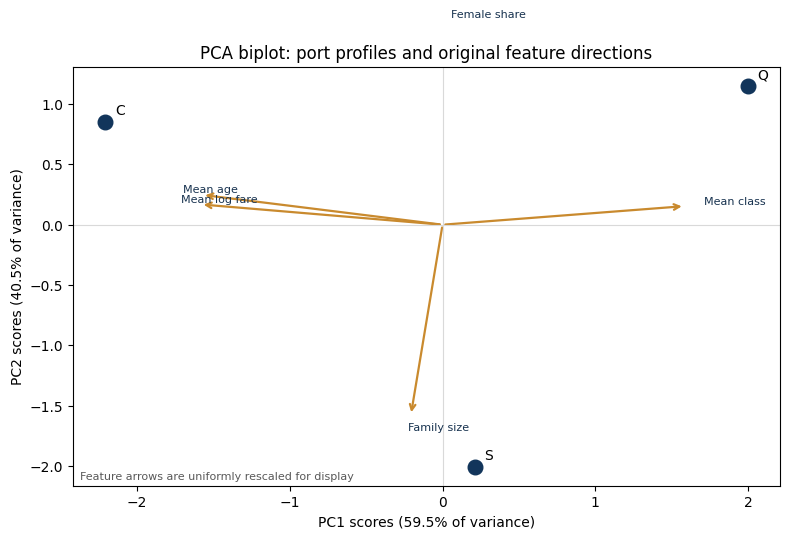

,PC1,PC2
Mean age,-0.988,0.155
Mean log fare,-0.994,0.106
Mean class,0.995,0.097
Family size,-0.130,-0.991
Female share,0.033,0.999


Two-component variance explained: 100.0%


In [21]:
profile_features = ["mean_age", "mean_log_fare", "mean_pclass", "mean_family_size", "female_share"]
profile_scaled = StandardScaler().fit_transform(profile[profile_features])
profile_pca = PCA(n_components=2)
profile_xy = profile_pca.fit_transform(profile_scaled)

profile_plot = pd.DataFrame(profile_xy, index=profile.index, columns=["PC1", "PC2"])
# Correlation of each original standardized feature with the two PC score axes.
feature_vectors = pd.DataFrame(
    np.corrcoef(profile_scaled.T, profile_xy.T)[:len(profile_features), len(profile_features):],
    index=profile_features,
    columns=["PC1", "PC2"],
)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(profile_plot["PC1"], profile_plot["PC2"], s=110, color="#12355B", zorder=3)
for port, row in profile_plot.iterrows():
    ax.annotate(port, (row["PC1"], row["PC2"]), xytext=(7, 5), textcoords="offset points")

# Scale all arrows by the same factor so their directions remain comparable.
# The displayed arrow lengths are for readability; see the unscaled correlations below.
score_span = np.abs(profile_xy).max()
vector_span = np.abs(feature_vectors.to_numpy()).max()
arrow_scale = 0.72 * score_span / vector_span
feature_labels = {
    "mean_age": "Mean age",
    "mean_log_fare": "Mean log fare",
    "mean_pclass": "Mean class",
    "mean_family_size": "Family size",
    "female_share": "Female share",
}
for feature, row in feature_vectors.iterrows():
    x, y = row["PC1"] * arrow_scale, row["PC2"] * arrow_scale
    ax.annotate(
        "", xy=(x, y), xytext=(0, 0),
        arrowprops={"arrowstyle": "->", "color": "#C98A2E", "lw": 1.6},
        zorder=2,
    )
    ax.text(x * 1.08, y * 1.08, feature_labels[feature], color="#17324F", fontsize=8)

ax.axhline(0, color="0.85", linewidth=0.8)
ax.axvline(0, color="0.85", linewidth=0.8)
ax.set_xlabel(f"PC1 scores ({profile_pca.explained_variance_ratio_[0]:.1%} of variance)")
ax.set_ylabel(f"PC2 scores ({profile_pca.explained_variance_ratio_[1]:.1%} of variance)")
ax.set_title("PCA biplot: port profiles and original feature directions")
ax.text(0.01, 0.01, "Feature arrows are uniformly rescaled for display", transform=ax.transAxes,
        fontsize=8, color="0.35", va="bottom")
plt.tight_layout()
plt.show()

display(feature_vectors.round(3).rename(index=feature_labels))
print("Two-component variance explained:",
      f"{profile_pca.explained_variance_ratio_.sum():.1%}")


### How to read the feature projection

The points are the three port-level passenger profiles projected onto PC1 and PC2. Each arrow shows how one original feature (after standardization) aligns with those two components. Its direction indicates the sign of its relationship with each PC; features pointing in similar directions tend to vary together across these profiles. The table reports the unscaled feature–component correlations. All arrows use one common visual scale, so compare their directions in the chart and use the table for their numerical values.

This is an exploratory view based on only three aggregate port profiles and five features. PCA here is unsupervised and does not establish that a representation improves survival prediction. The small number of profiles also makes these directions sensitive to the specific aggregation.

### What this PCA does and does not mean

The coordinates summarize differences among the selected port-level profiles. They are not a supervised embedding and do not establish that two ports are predictively interchangeable. There are only three profile rows; after centering, their rank is at most two, so two components can explain all their variation by construction.

In [22]:
# PCA directly on the three one-hot `embarked` columns is also uninformative here.
port_columns = [i for i, name in enumerate(feature_names) if name.startswith("embarked_")]
port_onehot = Z_train[:, port_columns].toarray()
port_onehot_pca = PCA(n_components=2).fit(port_onehot)
print("One-hot embarked dimensions:", port_onehot.shape[1])
print("Centered rank is at most:", min(2, port_onehot.shape[1] - 1))
print("Variance retained by two PCs:",
      f"{port_onehot_pca.explained_variance_ratio_.sum():.1%}")


One-hot embarked dimensions: 3
Centered rank is at most: 2
Variance retained by two PCs: 100.0%


## 7. What can we claim now?

**Supported now:** the chosen transformations preserve the observed categories; the one-hot matrix has a known size and density; unseen values have documented behavior; and the training data show specific category-level associations and profile differences.

**Not supported yet:** that an embedding beats one-hot, that `embarked` improves prediction alongside other features, or that the PCA coordinates improve generalization. No classifier has been trained in this notebook.

## 8. Class 18: controlled test of predictive contribution

When modeling has been introduced, test contribution by holding constant the data split, estimator, metric, and evaluation procedure. Compare a baseline without `embarked`, one-hot `embarked`, and any candidate embedding. Fit all learned transformations on training data only and evaluate on held-out data. Preselect a metric such as ROC AUC or balanced accuracy; report the change and the representation's added complexity. Repeat across folds or seeds if time allows.

A feature association or a visually separated PCA plot is a reason to form a hypothesis, not a substitute for this experiment.